# Final dataset check

This validates the finished dataset in `data/main.db` and `data/personas.db`: 2,000 simulated users, each with a persona Claude wrote from five random traits and their profile.

It answers three questions:
1. **Is the data sound?** Every user has one persona, and hidden text stays out of `main.db`.
2. **Does Jev respond to these personas?** Each user rates with their own persona, as they do in a real simulation, and the same users are rated with their original trait numbers as a comparison.
3. **Do the preferences make sense?** For example, do traditional personas favor religious targets?

Jev's results are saved to `final_persona_results.csv`, so re-running this doesn't call Jev again. Nothing here writes to the databases.

> **Historical notebook.** This ran before `interested_in` moved off profiles into the private `preferences` table, so it can't be re-run against the current databases. Its saved outputs are the record of the test. To re-run it, check out commit `f167a8f` and use the pre-migration copies in `backups/*-pre-migration/`.

## Setup

In [1]:
import json
import random
import re
import sqlite3
import sys
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "Data Generation")]

from manager import ProfileManager
from matching import is_compatible
from models import Persona
from paths import MAIN_DB, PERSONA_DB, SOURCE_MAIN_DB, SOURCE_PERSONA_DB
from raters import JEV_PRICE_PER_MTOK, JEV_QUESTION, _call_jev, build_rater_input
from written_personas import PERSONA_TRAITS

RESULTS_PATH = ROOT / "notebooks" / "final_persona_results.csv"
RERUN_JEV = False  # Set to True to call Jev again and replace the saved results. This costs money.

SEED = 7
N_RATERS = 20  # In each of the two groups.
N_TARGETS = 12
N_REPEATS = 6
N_REPEAT_PAIRS = 5
N_WORKERS = 8

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.bottom": False,
    "ytick.left": False,
    "text.color": INK,
    "font.size": 10,
    "figure.dpi": 120,
})

manager = ProfileManager(MAIN_DB, PERSONA_DB)
source = ProfileManager(SOURCE_MAIN_DB, SOURCE_PERSONA_DB)
profiles = manager.list_profiles()
personas = manager.personas.list_personas()
persona_by_user = {p.user_id: p for p in personas}

## 1. Is the data sound?

In [2]:
profile_ids = {p.user_id for p in profiles}
persona_ids = set(persona_by_user)
source_by_id = {p.user_id: p for p in source.list_profiles()}
descriptions = [p.description for p in personas]


def main_db_holds(text):
    with sqlite3.connect(f"file:{MAIN_DB}?mode=ro", uri=True) as conn:
        return any(text in str(value) for row in conn.execute("SELECT * FROM profiles") for value in row)


checks = {
    "Users": len(profile_ids),
    "Personas": len(persona_ids),
    "Users without a persona": len(profile_ids - persona_ids),
    "Personas without a user": len(persona_ids - profile_ids),
    "Duplicate personas": len(descriptions) - len(set(descriptions)),
    "Users marked as agents": sum(p.agent for p in profiles),
    "Profiles changed from the original data": sum(source_by_id[p.user_id] != p for p in profiles),
    "Sampled persona text found in main.db profiles": sum(main_db_holds(d) for d in descriptions[:25]),
}
pd.Series(checks, name="count").to_frame()

,count
Users,2000
Personas,2000
Users without a persona,0
Personas without a user,0
Duplicate personas,0
Users marked as agents,2000
Profiles changed from the original data,0
Sampled persona text found in main.db profiles,0


In [3]:
gender_groups = Counter((p.gender, p.interested_in) for p in profiles)
print("Gender and interest:", dict(gender_groups))
print("Looking for:", dict(Counter(p.looking_for for p in profiles)))

sentence_counts = Counter(len(re.findall(r"[.!?](?:\s|$)", d)) for d in descriptions)
lengths = [len(d) for d in descriptions]
print("Sentences:", dict(sorted(sentence_counts.items())))
print(f"Length: {min(lengths)} to {max(lengths)} characters, mean {np.mean(lengths):.0f}")

rng = random.Random(SEED)
word_sets = [set(re.findall(r"[a-z']+", d.lower())) for d in rng.sample(descriptions, 300)]
overlaps = [len(a & b) / len(a | b) for i, a in enumerate(word_sets) for b in word_sets[i + 1:]]
print(f"Word overlap between two personas: mean {np.mean(overlaps):.2f}, highest {max(overlaps):.2f}")
gendered = sum(bool(re.search(r"\b(he|she|him|his|her|hers|man|woman|men|women|guy|girl)\b", d, re.I)) for d in descriptions)
print(f"Personas using gendered words: {gendered} ({gendered / len(descriptions):.0%})")

Gender and interest: {('woman', 'men'): 961, ('man', 'women'): 989, ('man', 'men'): 29, ('woman', 'women'): 21}
Looking for: {'long-term': 609, 'short-term': 711, 'just a date': 680}
Sentences: {2: 919, 3: 1076, 4: 5}
Length: 385 to 950 characters, mean 590


Word overlap between two personas: mean 0.22, highest 0.44
Personas using gendered words: 344 (17%)


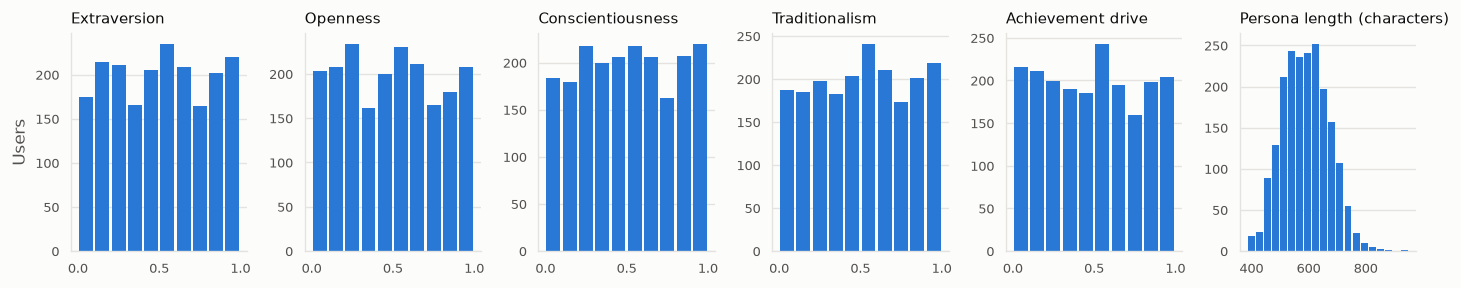

In [4]:
traits = pd.DataFrame([p.generation_seeds["traits"] for p in personas])
fig, axes = plt.subplots(1, len(PERSONA_TRAITS) + 1, figsize=(12, 2.5))
bins = np.linspace(0, 1, 11)
for ax, trait in zip(axes, PERSONA_TRAITS):
    ax.hist(traits[trait], bins=bins, color=BLUE, rwidth=0.86)
    ax.set_title(trait.replace("_", " ").capitalize(), fontsize=9)
    ax.grid(axis="x", visible=False)
    ax.tick_params(labelsize=8)
axes[-1].hist(lengths, bins=20, color=BLUE, rwidth=0.86)
axes[-1].set_title("Persona length (characters)", fontsize=9)
axes[-1].grid(axis="x", visible=False)
axes[-1].tick_params(labelsize=8)
axes[0].set_ylabel("Users")
fig.tight_layout()
plt.show()

### Example personas

In [5]:
for profile in random.Random(SEED).sample(profiles, 3):
    persona = persona_by_user[profile.user_id]
    print(profile.gender, profile.age, profile.religion, profile.major, profile.looking_for)
    print(persona.generation_seeds["traits"])
    print(persona.description)
    print()

woman 23 christian mechanical engineering long-term
{'extraversion': 0.97, 'openness': 0.81, 'conscientiousness': 0.35, 'traditionalism': 0.91, 'achievement_drive': 0.2}
They are a bubbly, outgoing 23-year-old who loves kabaddi, motor sports, and blacksmithing, and who keeps a steady, traditional Christian outlook on life despite a fairly unstructured schedule. They want a serious, long-term partner, ideally a Christian man of similar or taller height who has a stable, grounded path, whether in engineering or a trade, and who shares an appreciation for hands-on hobbies. They'd pass on anyone who isn't looking for something lasting, who dismisses faith, or who has no interest in the outdoors, competition, or working with their hands.

man 19 atheist economics just a date
{'extraversion': 0.12, 'openness': 0.6, 'conscientiousness': 0.02, 'traditionalism': 0.02, 'achievement_drive': 0.49}
They're a quiet, curious 19-year-old economics student at BU who works as a server, finds their footi

## 2. Does Jev respond to these personas?

Twenty men interested in women and twenty women interested in men each rate the same 12 targets, using their own profile. Each rater is rated twice, once with their written persona and once with their original trait-number persona, so only the persona differs.

| Effect | Question | What it means for a matcher |
| --- | --- | --- |
| **Rater** | Do some people like everyone more? | Little use, since it says nothing about who suits whom |
| **Target** | Are some people liked by everyone? | Popularity, which needs no hidden preferences |
| **Rater × target** | Do different people like different targets? | **The tastes a matcher has to learn** |

Profiles alone cause some rater × target differences, since `looking_for` and similar fields are visible to Jev. Comparing the two persona types shows what written personas add on top of that.

In [6]:
TRAIT_PERSONA_NOTE = "The trait-number personas go through the same Jev question, which no longer explains their 0 to 1 scale."


def plan_requests():
    rng = random.Random(SEED)
    plan = []
    groups = {"Men rating women": ("man", "women"), "Women rating men": ("woman", "men")}
    for group, (gender, interest) in groups.items():
        pool = [p for p in profiles if p.gender == gender and p.interested_in == interest]
        raters = rng.sample(pool, N_RATERS)
        targets = rng.sample([p for p in profiles if is_compatible(raters[0], p)], N_TARGETS)
        for condition in ("Written", "Trait numbers"):
            for rater_index, rater in enumerate(raters):
                written = persona_by_user[rater.user_id].description
                description = written if condition == "Written" else source.get_persona(rater.user_id).description
                for target_index, target in enumerate(targets):
                    plan.append((group, condition, rater_index, target_index, False, rater, description, target))
                if rater_index < N_REPEAT_PAIRS:
                    for _ in range(N_REPEATS):
                        plan.append((group, condition, rater_index, 0, True, rater, description, targets[0]))
    return plan


def rate(request):
    group, condition, rater_index, target_index, repeat, rater, description, target = request
    persona = Persona(user_id=rater.user_id, description=description)
    score, raw_output = _call_jev(build_rater_input(rater, persona, target))
    return {
        "group": group,
        "condition": condition,
        "rater": rater_index,
        "target": target_index,
        "repeat": repeat,
        "like": score,
        "input_tokens": json.loads(raw_output)["input_tokens"],
    }


plan = plan_requests()
if RERUN_JEV or not RESULTS_PATH.exists():
    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        results = pd.DataFrame(list(pool.map(rate, plan)))
    results.to_csv(RESULTS_PATH, index=False)
else:
    results = pd.read_csv(RESULTS_PATH)

print(f"{len(results)} ratings, about ${results['input_tokens'].sum() / 1e6 * JEV_PRICE_PER_MTOK:.3f} on Jev")
print(results.groupby("condition")["input_tokens"].mean().round(0).to_string())
print(TRAIT_PERSONA_NOTE)

1080 ratings, about $0.039 on Jev
condition
Trait numbers    971.0
Written          755.0
The trait-number personas go through the same Jev question, which no longer explains their 0 to 1 scale.


In [7]:
CONDITIONS = ["Trait numbers", "Written"]
grid_results = results[~results["repeat"]]


def effects_for(cell):
    grid = cell.pivot(index="rater", columns="target", values="like").values
    residuals = grid - grid.mean(axis=1, keepdims=True) - grid.mean(axis=0, keepdims=True) + grid.mean()
    n_raters, n_targets = grid.shape
    return {
        "rater": grid.mean(axis=1).std(ddof=1),
        "target": grid.mean(axis=0).std(ddof=1),
        "raw_interaction": np.sqrt((residuals**2).sum() / ((n_raters - 1) * (n_targets - 1))),
    }


rows = []
for (group, condition), cell in grid_results.groupby(["group", "condition"]):
    repeats = results[results["repeat"] & (results["group"] == group) & (results["condition"] == condition)]
    noise = np.sqrt(repeats.groupby("rater")["like"].var().mean())
    effect = effects_for(cell)
    effect["noise"] = noise
    effect["rater_x_target"] = np.sqrt(max(effect["raw_interaction"] ** 2 - noise**2, 0))
    rows.append({"group": group, "condition": condition, **effect})
effects = pd.DataFrame(rows)

table = effects.groupby("condition")[["rater_x_target", "rater", "target", "noise"]].mean().loc[CONDITIONS]
like = grid_results.groupby("condition")["like"]
table["mean_like"] = like.mean()
table["sd_like"] = like.std()
table["share_0.3_or_below"] = like.apply(lambda v: (v <= 0.3).mean())
table["share_0.7_or_above"] = like.apply(lambda v: (v >= 0.7).mean())
table.round(3)

,rater_x_target,rater,target,noise,mean_like,sd_like,share_0.3_or_below,share_0.7_or_above
condition,,,,,,,,
Trait numbers,0.115,0.06,0.033,0.011,0.585,0.132,0.046,0.267
Written,0.191,0.11,0.071,0.014,0.307,0.220,0.596,0.075


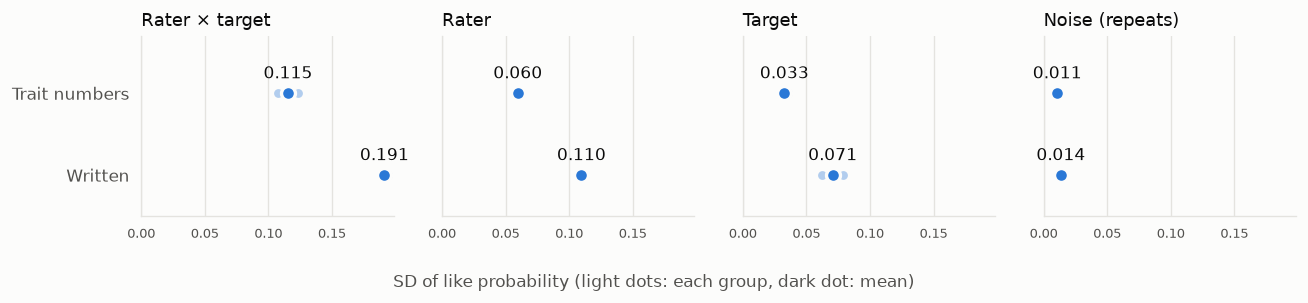

In [8]:
panels = [("rater_x_target", "Rater × target"), ("rater", "Rater"), ("target", "Target"), ("noise", "Noise (repeats)")]
fig, axes = plt.subplots(1, len(panels), figsize=(11, 2.5), sharey=True, sharex=True)
positions = np.arange(len(CONDITIONS))[::-1]
for ax, (column, title) in zip(axes, panels):
    for position, condition in zip(positions, CONDITIONS):
        values = effects[effects["condition"] == condition][column]
        ax.scatter(values, [position] * len(values), s=28, color=BLUE, alpha=0.35, linewidths=0)
        ax.scatter(values.mean(), position, s=70, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
        ax.annotate(f"{values.mean():.3f}", (values.mean(), position), xytext=(0, 9), textcoords="offset points", ha="center")
    ax.set_title(title)
    ax.set_xlim(left=0)
    ax.set_ylim(-0.5, len(CONDITIONS) - 0.3)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_yticks(positions, CONDITIONS)
fig.supxlabel("SD of like probability (light dots: each group, dark dot: mean)", color=MUTED, fontsize=10)
fig.tight_layout()
plt.show()

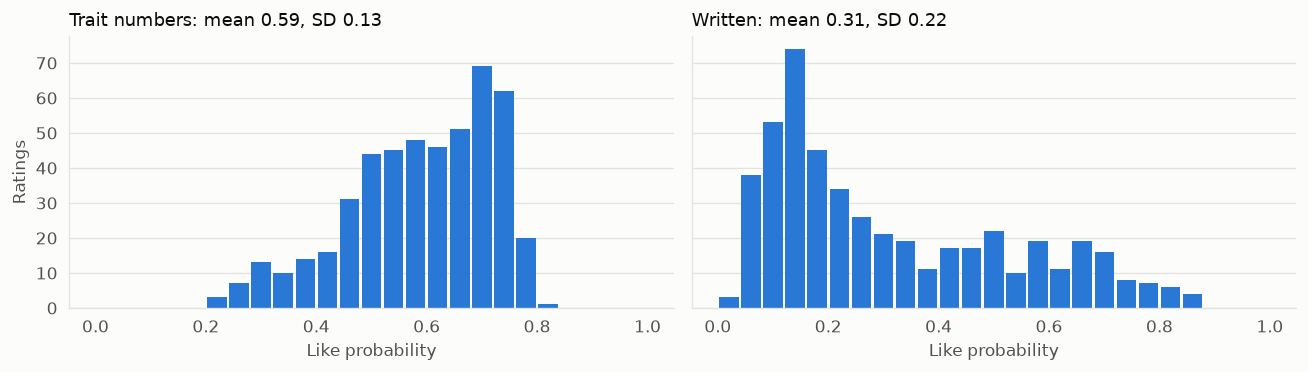

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True, sharey=True)
bins = np.linspace(0, 1, 26)
for ax, condition in zip(axes, CONDITIONS):
    values = grid_results[grid_results["condition"] == condition]["like"]
    ax.hist(values, bins=bins, color=BLUE, rwidth=0.88)
    ax.set_title(f"{condition}: mean {values.mean():.2f}, SD {values.std():.2f}")
    ax.set_xlabel("Like probability")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Ratings")
fig.tight_layout()
plt.show()

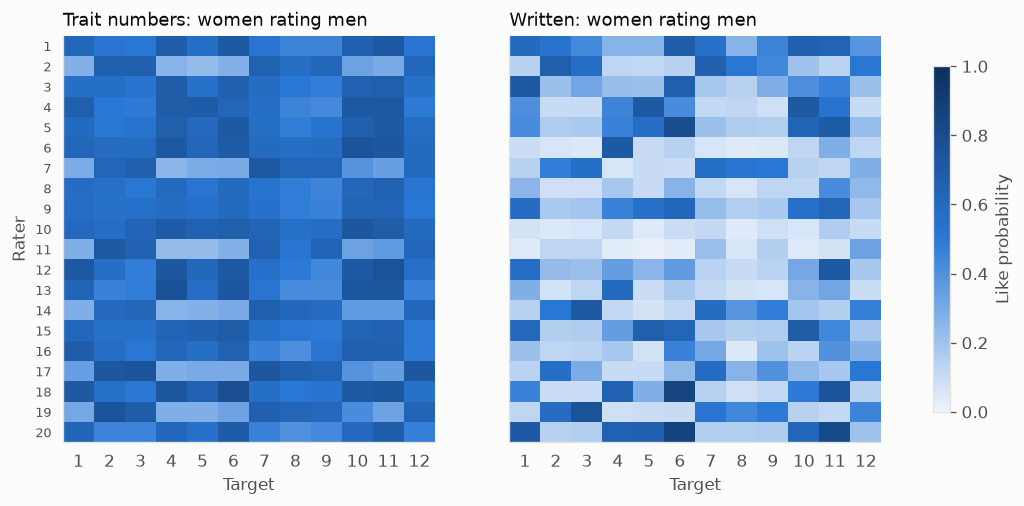

In [10]:
shades = LinearSegmentedColormap.from_list("like", ["#eef4fc", BLUE, "#0d2f5c"])
group = "Women rating men"
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, condition in zip(axes, CONDITIONS):
    cell = grid_results[(grid_results["condition"] == condition) & (grid_results["group"] == group)]
    grid = cell.pivot(index="rater", columns="target", values="like").values
    image = ax.imshow(grid, cmap=shades, vmin=0, vmax=1, aspect="auto")
    ax.set_title(f"{condition}: {group.lower()}")
    ax.set_xlabel("Target")
    ax.set_xticks(range(N_TARGETS), range(1, N_TARGETS + 1))
    ax.grid(False)
axes[0].set_ylabel("Rater")
axes[0].set_yticks(range(N_RATERS), range(1, N_RATERS + 1), fontsize=8)
fig.colorbar(image, ax=axes, label="Like probability", shrink=0.85)
plt.show()

## 3. Do the preferences make sense?

Strong effects could still be arbitrary, so these checks compare ratings with facts about the pair. They use only written-persona ratings and call no API. The comparison is between pairs, so other differences between people can affect it too.

In [11]:
lookup = []
for group, condition, rater_index, target_index, repeat, rater, _, target in plan:
    if condition == "Written" and not repeat:
        lookup.append({
            "group": group,
            "rater": rater_index,
            "target": target_index,
            "traditionalism": persona_by_user[rater.user_id].generation_seeds["traits"]["traditionalism"],
            "religious_target": target.religion not in ("atheist", "agnostic", "spiritual"),
            "same_religion": rater.religion == target.religion,
            "same_goal": rater.looking_for == target.looking_for,
            "shared_interest_or_club": bool(set(rater.interests + rater.clubs) & set(target.interests + target.clubs)),
        })
written = pd.DataFrame(lookup).merge(grid_results[grid_results["condition"] == "Written"], on=["group", "rater", "target"])
written["traditionalism_group"] = pd.cut(written["traditionalism"], [-1, 0.33, 0.66, 2], labels=["Low", "Middle", "High"])

tradition = written.pivot_table(index="traditionalism_group", columns="religious_target", values="like", observed=False)
tradition.columns = ["Non-religious target", "Religious target"]
tradition["difference"] = tradition["Religious target"] - tradition["Non-religious target"]

matches = []
for column, label in (("same_goal", "Same relationship goal"), ("same_religion", "Same religion")):
    grouped = written.groupby(column)["like"].agg(["mean", "size"])
    matches.append({"pair": label, "like_if_yes": grouped.loc[True, "mean"], "like_if_no": grouped.loc[False, "mean"], "pairs_yes": int(grouped.loc[True, "size"]), "pairs_no": int(grouped.loc[False, "size"])})
matches = pd.DataFrame(matches).set_index("pair")
matches["difference"] = matches["like_if_yes"] - matches["like_if_no"]
print("Traditionalism and religious targets:")
print(tradition.round(3).to_string())
print()
print("Whether pairs match:")
print(matches.round(3).to_string())

Traditionalism and religious targets:
                      Non-religious target  Religious target  difference
traditionalism_group                                                    
Low                                  0.418             0.325      -0.093
Middle                               0.372             0.305      -0.067
High                                 0.229             0.270       0.041

Whether pairs match:
                        like_if_yes  like_if_no  pairs_yes  pairs_no  difference
pair                                                                            
Same relationship goal        0.451       0.239        154       326       0.212
Same religion                 0.405       0.297         44       436       0.107


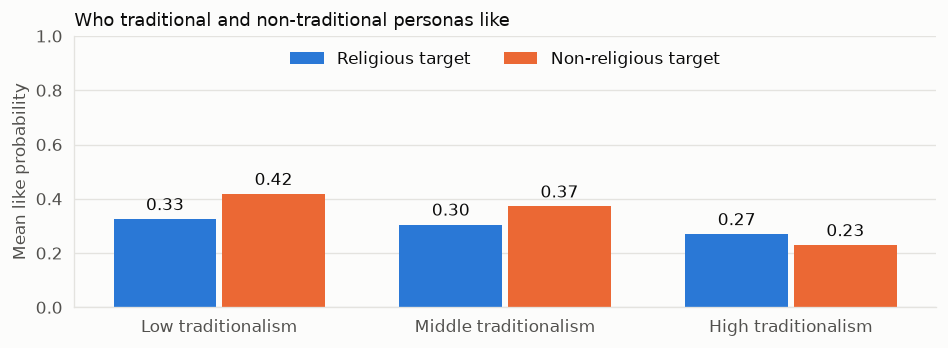

In [12]:
fig, ax = plt.subplots(figsize=(8, 3))
x = np.arange(len(tradition))
width = 0.36
for offset, (column, color) in zip([-width / 2 - 0.01, width / 2 + 0.01], [("Religious target", BLUE), ("Non-religious target", ORANGE)]):
    bars = ax.bar(x + offset, tradition[column], width, color=color, label=column)
    ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_xticks(x, [f"{name} traditionalism" for name in tradition.index])
ax.set_ylim(0, 1)
ax.set_ylabel("Mean like probability")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, ncols=2, loc="upper center")
ax.set_title("Who traditional and non-traditional personas like")
fig.tight_layout()
plt.show()

## What this shows

**The dataset is sound and ready to use. Written personas give a matcher more to learn from, though by less than the earlier persona-swap test suggested.**

| Measure | Trait numbers | Written |
| --- | --- | --- |
| Rater × target interaction | 0.115 | **0.191** |
| Rater effect | 0.060 | 0.110 |
| Target effect | 0.033 | 0.071 |
| Noise (repeats) | 0.011 | 0.014 |
| Mean like probability | 0.585 | **0.307** |
| Ratings at 0.3 or below | 5% | **60%** |
| Ratings at 0.7 or above | 27% | **8%** |

- **Data:** all 2,000 users have exactly one persona, no personas are duplicated, profiles match the original data, and the sampled persona text wasn't in `main.db` profiles.
- **Real tastes:** different people like different targets, at about 14 times noise. Trait numbers already reached 0.115 here because raters' own profiles differ, so written personas add about 1.7 times on top of that, not the near 4 times seen when only the persona changed.
- **Sense checks:** pairs with the same relationship goal score 0.21 higher, and pairs with the same religion score 0.11 higher. Part of this could come from Jev reading both profiles rather than from the personas.
- **Traditionalism is a weaker signal than in the sample:** the gap moves in the expected direction, from -0.09 for low to +0.04 for high, but high-traditionalism personas only slightly favor religious targets, and they like fewer people overall.

**Limits:**
- **Low like rates:** written personas are picky, so most ratings are low. If you draw simulated swipes, expect about 3 in 10 likes, and mutual matches will be rarer.
- **Uneven comparison:** the Jev question no longer explains the trait-number scale, which may slightly weaken the trait-number result.
- **Small test:** 40 raters and 24 targets, split across two groups, out of 2,000 users.
- **Writing quality:** 17% of personas use gendered words, despite being told not to. An automated check flagged 7 possible conflicts with `interested_in`, and on reading them none were real. About 30 use trait words like "openness", and some name very specific clubs that few profiles could match.
- **Still simulated:** these are Jev's estimates of made-up people, not real behavior.
